# Laboratorio Evaluado: WBCD y Evaluación Multimodelo

**Reto Autónomo: Clínica Oncológica**

Eres el Consultor IA de un hospital. El dataset WBCD contiene radios y perímetros de células. Debes entrenar k-NN y Árboles de Decisión, y validar qué pasa si no escalas los datos.

## 1. Carga de Datos y Exploración

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score

# Nombres de columnas del WDBC: id, diagnosis y 30 features (mean, se, worst de 10 medidas)
base = ["radius", "texture", "perimeter", "area", "smoothness",
        "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
cols = ["id", "diagnosis"] + [f"{b}_{s}" for s in ["mean", "se", "worst"] for b in base]

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
try:
    df_wbcd = pd.read_csv(URL, header=None, names=cols)
    origen = "UCI (descarga directa)"
except Exception as e:
    # Respaldo sin internet: scikit-learn trae exactamente el mismo dataset WDBC (569 filas, 30 features)
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer()
    df_wbcd = pd.DataFrame(data.data, columns=cols[2:])  # mismo orden: mean, se, worst
    df_wbcd.insert(0, "diagnosis", np.where(data.target == 0, "M", "B"))  # en sklearn: 0 = maligno
    df_wbcd.insert(0, "id", range(len(df_wbcd)))
    origen = "scikit-learn load_breast_cancer (mismo dataset WDBC)"

print("Fuente de datos:", origen)
print("Dimensiones:", df_wbcd.shape)
print(df_wbcd["diagnosis"].value_counts())
df_wbcd.head()

Fuente de datos: UCI (descarga directa)
Dimensiones: (569, 32)
diagnosis
B    357
M    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Preprocesamiento

In [ ]:
# Diagnosis a binario: M (maligno) = 1, B (benigno) = 0
df_wbcd["target"] = (df_wbcd["diagnosis"] == "M").astype(int)

# X (features) e y (target); se descartan id y diagnosis
X = df_wbcd.drop(columns=["id", "diagnosis", "target"])
y = df_wbcd["target"]

# 80% train / 20% test, estratificado para conservar la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Malignos en test:", int(y_test.sum()), "| Benignos en test:", int((y_test == 0).sum()))

Train: (455, 30) | Test: (114, 30)
Malignos en test: 42 | Benignos en test: 72


## 3. Escalamiento (Solo para k-NN)

In [ ]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit SOLO con train (evita fuga de información)
X_test_sc = scaler.transform(X_test)         # en test solo transform

# Para ver por qué importa escalar: rangos muy distintos entre variables
print(X_train[["area_mean", "smoothness_mean"]].describe().loc[["min", "max"]])

     area_mean  smoothness_mean
min      143.5          0.06251
max     2501.0          0.16340


## 4. Modelado y Matrices de Confusión

In [ ]:
# k-NN con datos escalados (lo correcto)
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_sc, y_train)
pred_knn = knn.predict(X_test_sc)

# k-NN SIN escalar (experimento pedido por el reto)
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
pred_knn_raw = knn_raw.predict(X_test)

# Árbol de decisión (sin escalar, no lo necesita)
tree = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)
pred_tree = tree.predict(X_test)

# Árbol con datos escalados, para comprobar que no cambia nada
tree_sc = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train_sc, y_train)
pred_tree_sc = tree_sc.predict(X_test_sc)

modelos = {
    "k-NN escalado": pred_knn,
    "k-NN SIN escalar": pred_knn_raw,
    "Árbol (sin escalar)": pred_tree,
    "Árbol (escalado)": pred_tree_sc,
}

for nombre, pred in modelos.items():
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"=== {nombre} ===")
    print("Matriz de confusión [filas = real, columnas = predicho] (0=Benigno, 1=Maligno)")
    print(cm)
    print(f"VN={tn}  FP={fp}  FN={fn}  VP={tp}")
    print(f"Exactitud={accuracy_score(y_test, pred):.3f} | "
          f"Recall maligno={recall_score(y_test, pred):.3f} | "
          f"Precisión maligno={precision_score(y_test, pred):.3f}\n")

=== k-NN escalado ===
Matriz de confusión [filas = real, columnas = predicho] (0=Benigno, 1=Maligno)
[[71  1]
 [ 4 38]]
VN=71  FP=1  FN=4  VP=38
Exactitud=0.956 | Recall maligno=0.905 | Precisión maligno=0.974

=== k-NN SIN escalar ===
Matriz de confusión [filas = real, columnas = predicho] (0=Benigno, 1=Maligno)
[[71  1]
 [ 9 33]]
VN=71  FP=1  FN=9  VP=33
Exactitud=0.912 | Recall maligno=0.786 | Precisión maligno=0.971

=== Árbol (sin escalar) ===
Matriz de confusión [filas = real, columnas = predicho] (0=Benigno, 1=Maligno)
[[70  2]
 [ 8 34]]
VN=70  FP=2  FN=8  VP=34
Exactitud=0.912 | Recall maligno=0.810 | Precisión maligno=0.944

=== Árbol (escalado) ===
Matriz de confusión [filas = real, columnas = predicho] (0=Benigno, 1=Maligno)
[[70  2]
 [ 8 34]]
VN=70  FP=2  FN=8  VP=34
Exactitud=0.912 | Recall maligno=0.810 | Precisión maligno=0.944



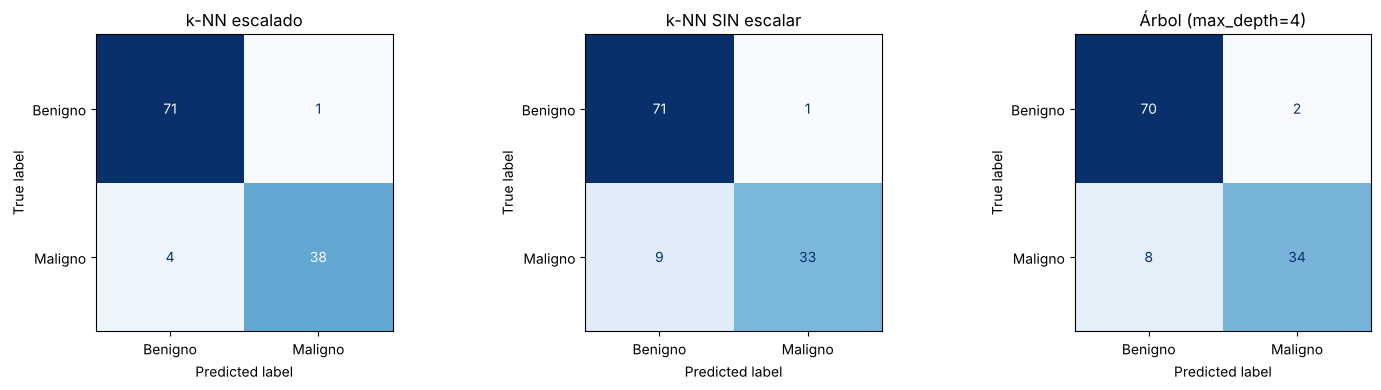

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, pred) in zip(axes, [("k-NN escalado", pred_knn),
                                     ("k-NN SIN escalar", pred_knn_raw),
                                     ("Árbol (max_depth=4)", pred_tree)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Benigno", "Maligno"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

In [ ]:
# ¿Qué variables usa realmente el árbol?
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(6).round(3))

perimeter_worst         0.784
concave_points_worst    0.073
texture_mean            0.031
smoothness_worst        0.027
area_mean               0.024
texture_worst           0.017
dtype: float64


## Evaluación Teórica / Decisión de Negocios

1. En este escenario médico, ¿qué implica un Error Tipo II (Falso Negativo) y por qué cuesta vidas?
2. ¿Por qué crees que el Árbol de Decisión no falló estrepitosamente incluso si no hubieses escalado los datos?

*Escribe tu respuesta aquí:*

**Respuesta 1 (Error Tipo II).** Un falso negativo es cuando el modelo dice que el tumor es benigno y en realidad es maligno. A la paciente le dicen que está bien, así que no se trata, y mientras tanto el cáncer sigue creciendo. Es mucho más grave que un falso positivo, que solo le da un susto y unos exámenes de más. En mis resultados, el k-NN escalado dejó pasar 4 casos malignos, el árbol 8 y el k-NN sin escalar 9. Por eso en un hospital lo que más hay que cuidar es tener pocos falsos negativos.

**Respuesta 2 (Árbol sin escalar).** El árbol solo hace preguntas sencillas, como “¿el perímetro es mayor que tal número?”, y las hace de una medida a la vez. Nunca compara una medida con otra, así que no le molesta que el área tenga números grandes y la suavidad números chicos. Por eso me dio exactamente el mismo resultado con y sin escalar. Al k-NN sí le afecta, porque calcula distancias y las medidas con números grandes terminan mandando sobre las demás. Sin escalar, pasó de 4 a 9 falsos negativos.
